# A06 — Outros detectores de doublets: Solo e cxds

## Por que mais dois métodos

A03 mostrou que o Scrublet quase não enxerga doublets nesta população: dos 70
doublets T + B confirmados por marcadores e por UMIs, o threshold automático
pega 1. Isso deixa aberta a possibilidade de que outro método encontre
doublets que o Scrublet perde. Dois métodos com lógicas diferentes:

| método | como decide | o que pode enxergar | o que não enxerga |
| --- | --- | --- | --- |
| **Solo** (scvi-tools) | um autoencoder variacional (scVI) aprende o espaço latente; um classificador separa células observadas de doublets simulados | doublets cujo perfil difere das células sozinhas no espaço latente | doublets de duas células do mesmo estado (o latente não guarda o tamanho da biblioteca) |
| **cxds** (scds) | sem simulação: pares de genes que quase nunca aparecem juntos na mesma célula; a célula que expressa os dois lados soma pontos | doublets heterotípicos, inclusive entre populações raras | doublets de células iguais; programas que não sejam mutuamente exclusivos |

## Como avaliar sem verdade conhecida

Não há genótipo nem hashing, então nenhum método pode ser "conferido" de
forma absoluta. Usam-se quatro referências internas:

* **positivos validados** — os 70 barcodes T + B de A03 (marcadores das duas
  linhagens e UMIs ≈ soma de uma B e uma T);
* **negativos de controle** — barcodes com sinal de B **sem** sinal de T (células
  B sozinhas): são heterotípicos em relação ao resto, mas não são doublets;
* **conteúdo de RNA** — um doublet carrega mais UMIs que uma célula sozinha;
* **taxa esperada do 10x** — ~0,8% por 1.000 células recuperadas.

E a pergunta que motivou tudo: algum método indica **excesso** de doublets
nas bibliotecas de baixa recuperação?

## Dados

As 35.126 células que passaram no filtro MAD de A01 — antes da remoção pelo
Scrublet, como em A03 —, com as contagens do Cell Ranger. Os clusters e o
UMAP são os da V3 (A04).

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import logging
import time
import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import roc_auc_score

from functions import config, doublets as db, fmt as F, io, pipeline as pl, plotting
from functions.issues import IssueLog, show

for name in ("lightning", "lightning.pytorch", "lightning.fabric", "scvi", "pytorch_lightning"):
    logging.getLogger(name).setLevel(logging.ERROR)

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "A06_doublets_solo_cxds"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
METODO_COR = {"Scrublet": plotting.CATEGORICAL[0], "Solo": plotting.CATEGORICAL[1], "cxds": plotting.CATEGORICAL[2]}

In [2]:
cel = io.load_data("A01_preprocessamento", "celulas_qc")
fd = io.load_data("A03_doublets_recuperacao", "flags_doublets")
fd.index = fd["library_id"] + "|" + fd["barcode"]

caminho = io.data_path("A04_processamento_integracao", "reseq_integrado", "h5ad")
ig = ad.read_h5ad(caminho, backed="r")
hvg_ids = ig.var.loc[ig.var["highly_variable"].astype(bool), "gene_ids"].to_numpy()
v3 = pd.DataFrame({"cluster": ig.obs["leiden"].astype(str).to_numpy()}, index=ig.obs["cell_key"].to_numpy())
umap = pd.DataFrame(np.asarray(ig.obsm["X_umap"]), index=v3.index, columns=["x", "y"])
ig.file.close()

partes = []
for lib in LIBS:
    m = io.read_filtered(lib)
    q = cel[(cel["library_id"] == lib) & cel["passou_mad"]]
    idx = pd.Index(m["barcodes"]).get_indexer(q["barcode"])
    assert (idx >= 0).all()
    a = ad.AnnData(X=m["X"][idx].astype(np.float32),
                   obs=pd.DataFrame({"library_id": lib, "barcode": q["barcode"].to_numpy(),
                                     "scrublet_score": q["doublet_score"].to_numpy()}),
                   var=pd.DataFrame({"gene_name": m["gene_names"]}, index=m["gene_ids"]))
    partes.append(a)
    del m
adata = ad.concat(partes, merge="first")
adata.obs_names = (adata.obs["library_id"].astype(str) + "|" + adata.obs["barcode"].astype(str)).to_numpy()
del partes
assert adata.obs_names.isin(fd.index).all() and len(fd) == adata.n_obs

pc = adata.obs[["library_id", "barcode", "scrublet_score"]].copy()
pc["library_id"] = pc["library_id"].astype(str)
pc["umis"] = np.asarray(adata.X.sum(axis=1)).ravel()
pc = pc.join(fd[["com_B", "duplo_TB", "scrublet_auto", "scrublet_calibrado"]])
pc["b_sozinha"] = pc["com_B"] & ~pc["duplo_TB"]
pc["cluster_v3"] = v3["cluster"].reindex(pc.index).to_numpy()
n_lib = pc.groupby("library_id").size().reindex(LIBS)
taxa = pd.Series({l: db.expected_doublet_rate_10x(int(n_lib[l])) for l in LIBS})
pc["umis_rel"] = pc["umis"] / pc.groupby("library_id")["umis"].transform("median")
print(f"{F.n(adata.n_obs)} células pós-MAD × {F.n(adata.n_vars)} genes · {plotting.N_DESIGN}")
print(f"positivos validados (T + B): {int(pc['duplo_TB'].sum())}; células B sozinhas: {int(pc['b_sozinha'].sum())}; "
      f"doublets esperados pela taxa do 10x: {F.n((taxa * n_lib).sum())}")

35.126 células pós-MAD × 38.606 genes · 14 bibliotecas · 7 pacientes
positivos validados (T + B): 70; células B sozinhas: 196; doublets esperados pela taxa do 10x: 1.554


## 1. cxds

O cxds roda por biblioteca, como no pacote: cada biblioteca tem os seus 500
genes de maior variância de presença e os seus pares mutuamente exclusivos.
O score não tem limiar natural; a chamada usa o mesmo critério do Scrublet
calibrado em A03 — marcar, em cada biblioteca, a fração que a taxa do 10x
prevê.

A conta é feita por uma reimplementação em Python (`functions/doublets.cxds`),
conferida antes contra o pacote `scds` do R numa biblioteca.

In [3]:
alvo = "CTH92_NS"
sub = adata[adata.obs["library_id"] == alvo]
ref_r = db.cxds_r(sub.X, r_lib=str(config.SCDS_R_LIB)) if config.SCDS_R_LIB.exists() else None
meu = db.cxds(sub.X)["score"]
if ref_r is not None:
    dif = float(np.max(np.abs(meu - ref_r) / np.maximum(np.abs(ref_r), 1e-9)))
    rho_r = float(stats.spearmanr(meu, ref_r).statistic)
    conf_cxds = f"scds {alvo}: {F.n(len(meu))} células; maior diferença relativa {dif:.1e}; Spearman {F.f(rho_r, 6)}"
    assert rho_r > 0.999, "a reimplementação do cxds não reproduz o scds"
else:
    conf_cxds = "scds indisponível no R: score só pela reimplementação"
print(conf_cxds)

scds CTH92_NS: 812 células; maior diferença relativa 5.3e-02; Spearman 0,999931


In [4]:
t0 = time.time()
nomes = adata.var["gene_name"].to_numpy()
classe_gene = pl.classify_genes(nomes, {"marcador B": set(config.MARKERS_B), "marcador T": set(config.MARKERS_T)})
classe_gene = classe_gene.to_numpy()
pc["cxds_score"] = np.nan
pares_top, pares_celula = [], []
for lib in LIBS:
    m = (pc["library_id"] == lib).to_numpy()
    r = db.cxds(adata.X[m])
    pc.loc[m, "cxds_score"] = r["score"]
    g, S = r["genes"], r["S"]
    iu = np.triu_indices_from(S, k=1)
    ordem = np.argsort(-S[iu])[:25]
    for k in ordem:
        i, j = iu[0][k], iu[1][k]
        pares_top.append({"library_id": lib, "gene_1": nomes[g[i]], "gene_2": nomes[g[j]], "peso": float(S[i, j]),
                          "classes": " × ".join(sorted([classe_gene[g[i]], classe_gene[g[j]]]))})
    thr = db.threshold_by_expected_rate(r["score"], taxa[lib])
    chamadas = np.flatnonzero(r["score"] >= thr)
    Bp = (adata.X[m][:, g] > 0).toarray()
    for c in chamadas:
        on = np.flatnonzero(Bp[c])
        sub_S = S[np.ix_(on, on)]
        a_, b_ = np.unravel_index(np.argmax(sub_S), sub_S.shape)
        i, j = on[a_], on[b_]
        pares_celula.append({"library_id": lib, "par": f"{nomes[g[i]]} × {nomes[g[j]]}",
                             "classes": " × ".join(sorted([classe_gene[g[i]], classe_gene[g[j]]]))})
pc["cxds_pct"] = pc.groupby("library_id")["cxds_score"].rank(pct=True)
thr_cx = pc.groupby("library_id")["cxds_score"].apply(lambda s: db.threshold_by_expected_rate(s.to_numpy(), taxa[s.name]))
pc["cxds_calibrado"] = pc["cxds_score"] >= pc["library_id"].map(thr_cx)
pares_top = pd.DataFrame(pares_top)
pares_celula = pd.DataFrame(pares_celula)
io.save_table(pares_top, NB, "cxds_pares_mais_exclusivos", index=False,
              description="Os 25 pares de genes mais mutuamente exclusivos em cada biblioteca (cxds)")
cls_top = pares_top["classes"].value_counts(normalize=True)
cls_cel = pares_celula["classes"].value_counts(normalize=True)
io.save_table(pd.DataFrame({"pares mais exclusivos": cls_top, "par que mais pesa nas células chamadas": cls_cel}).fillna(0),
              NB, "cxds_classes_dos_pares", description="Classes dos genes nos pares que dirigem o cxds")
print(f"cxds em {time.time() - t0:.0f} s; {int(pc['cxds_calibrado'].sum())} chamadas calibradas")
print("classes dos pares mais exclusivos:", "; ".join(f"{c} {F.pct(x, 0)}" for c, x in cls_top.head(6).items()))
print("par que mais pesa em cada célula chamada:", "; ".join(f"{c} {F.pct(x, 0)}" for c, x in cls_cel.head(6).items()))
pares_celula["par"].value_counts().head(12)

cxds em 3 s; 1558 chamadas calibradas
classes dos pares mais exclusivos: outros × outros 100%; marcador T × outros 0%
par que mais pesa em cada célula chamada: outros × outros 100%


par
PHACTR2 × IGF1R    661
IGF1R × ERN1       184
CD7 × TALAM1       157
IFIT3 × TSC22D3    135
S100A4 × IGF1R      83
IGF1R × COTL1       72
NIBAN1 × ADTRP      29
IGF1R × SLAMF1      29
ACTN1 × NIBAN1      23
CMTM8 × SAMD3       21
TXK × TNFAIP3       19
TALAM1 × FXYD5      18
Name: count, dtype: int64

## 2. Solo

Um modelo scVI é treinado com todas as células (os 2.000 genes variáveis da
V3, lote = biblioteca) e, como recomenda o scvi-tools, um classificador Solo
é treinado **por biblioteca** (`restrict_to_batch`), com o dobro de doublets
simulados a partir das células daquela biblioteca. A chamada padrão do Solo
é probabilidade de doublet acima de 0,5; a calibrada usa a taxa do 10x, como
nos outros métodos.

In [5]:
import scvi
import torch

scvi.settings.seed = config.RANDOM_STATE
scvi.settings.verbosity = logging.ERROR
for name in list(logging.root.manager.loggerDict):
    if name.startswith(("lightning", "pytorch_lightning")):
        logging.getLogger(name).setLevel(logging.ERROR)
sv = adata[:, adata.var_names.isin(hvg_ids)].copy()
sv.obs["library_id"] = sv.obs["library_id"].astype("category")
assert sv.n_vars == len(hvg_ids)
t0 = time.time()
scvi.model.SCVI.setup_anndata(sv, batch_key="library_id")
modelo = scvi.model.SCVI(sv)
modelo.train(early_stopping=True, enable_progress_bar=False)
hist = modelo.history
epocas_scvi = len(hist["elbo_train"])
print(f"scVI: {F.n(sv.n_obs)} células × {F.n(sv.n_vars)} genes; {epocas_scvi} épocas em {time.time() - t0:.0f} s "
      f"({'GPU' if torch.cuda.is_available() else 'CPU'}); ELBO de validação final "
      f"{F.f(float(hist['elbo_validation'].iloc[-1, 0]), 1)}")

t0 = time.time()
solo_p, solo_info = {}, []
for lib in LIBS:
    s = scvi.external.SOLO.from_scvi_model(modelo, restrict_to_batch=lib)
    s.train(enable_progress_bar=False)
    p = s.predict(soft=True)
    solo_p.update(p["doublet"].to_dict())
    solo_info.append({"library_id": lib, "celulas": int(n_lib[lib]), "epocas": len(next(iter(s.history.values()))),
                      "p_mediana": float(p["doublet"].median()), "chamadas_padrao": int((p["doublet"] > 0.5).sum())})
pc["solo_p"] = pd.Series(solo_p).reindex(pc.index).to_numpy()
assert pc["solo_p"].notna().all()
pc["solo_padrao"] = pc["solo_p"] > 0.5
pc["solo_pct"] = pc.groupby("library_id")["solo_p"].rank(pct=True)
thr_solo = pc.groupby("library_id")["solo_p"].apply(lambda s: db.threshold_by_expected_rate(s.to_numpy(), taxa[s.name]))
pc["solo_calibrado"] = pc["solo_p"] >= pc["library_id"].map(thr_solo)
pc["consenso"] = pc[["scrublet_calibrado", "solo_calibrado", "cxds_calibrado"]].astype(int).sum(axis=1) >= 2
solo_info = pd.DataFrame(solo_info).set_index("library_id")
solo_info["frac_padrao"] = solo_info["chamadas_padrao"] / solo_info["celulas"]
solo_info["taxa_esperada_10x"] = taxa
io.save_table(solo_info, NB, "solo_por_biblioteca", description="Solo por biblioteca: épocas, probabilidade mediana e chamadas com p > 0,5")
print(f"Solo nas 14 bibliotecas em {time.time() - t0:.0f} s")
solo_info.round(3)

Seed set to 42


scVI: 35.126 células × 2.000 genes; 228 épocas em 302 s (GPU); ELBO de validação final 752,1


Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.319. Signaling Trainer to stop.


Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.481. Signaling Trainer to stop.


Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.135. Signaling Trainer to stop.


...

Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.165. Signaling Trainer to stop.


Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.157. Signaling Trainer to stop.


Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.242. Signaling Trainer to stop.
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.601. Signaling Trainer to stop.


Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.178. Signaling Trainer to stop.
Solo nas 14 bibliotecas em 259 s


,celulas,epocas,p_mediana,chamadas_padrao,frac_padrao,taxa_esperada_10x
library_id,,,,,,
CTH92_NS,812,262,0.139,149,0.183,0.006
CTH92_ML,1538,203,0.340,520,0.338,0.012
CTH94_NS,5579,142,0.005,543,0.097,0.045
CTH94_ML,500,400,0.076,55,0.110,0.004
CTH97_NS,1517,188,0.022,160,0.105,0.012
CTH97_ML,4696,379,0.239,1357,0.289,0.038
PB20_NS,602,228,0.110,74,0.123,0.005
PB20_ML,781,337,0.055,81,0.104,0.006
PB21_NS,3666,114,0.017,344,0.094,0.029


## 3. Os métodos lado a lado

Cinco chamadas: Scrublet com threshold automático (a do original) e
calibrado (A03), Solo com o limiar padrão e calibrado, e cxds calibrado. Para
comparar os scores sem depender de limiar, cada score é convertido em
percentil dentro da biblioteca e usado para separar os 70 doublets T + B
validados do resto (área sob a curva ROC: 0,5 = acaso, 1 = separação
perfeita). O controle negativo são as células B sozinhas: um método que as
chama está reagindo a "ser diferente", não a "ser duas células".

In [6]:
pc["scrublet_pct"] = pc.groupby("library_id")["scrublet_score"].rank(pct=True)
CHAMADAS = {"Scrublet automático": "scrublet_auto", "Scrublet calibrado": "scrublet_calibrado",
            "Solo padrão (p > 0,5)": "solo_padrao", "Solo calibrado": "solo_calibrado", "cxds calibrado": "cxds_calibrado",
            "consenso (≥ 2 dos 3 calibrados)": "consenso"}
SCORES = {"Scrublet": "scrublet_pct", "Solo": "solo_pct", "cxds": "cxds_pct"}
n_tb, n_bs = int(pc["duplo_TB"].sum()), int(pc["b_sozinha"].sum())
linhas = []
for nome, col in CHAMADAS.items():
    c = pc[col].astype(bool)
    k_tb, k_bs = int(c[pc["duplo_TB"]].sum()), int(c[pc["b_sozinha"]].sum())
    ic = db.wilson(k_tb, n_tb)
    frac_lib = c.groupby(pc["library_id"]).mean().reindex(LIBS)
    linhas.append({"método": nome, "chamadas": int(c.sum()), "% das células": float(c.mean()),
                   "T + B validados pegos": f"{k_tb}/{n_tb}", "sensibilidade": k_tb / n_tb,
                   "IC 95% inf": ic[0], "IC 95% sup": ic[1],
                   "B sozinhas chamadas": f"{k_bs}/{n_bs}",
                   "UMIs das chamadas (× mediana da biblioteca)": float(pc.loc[c, "umis_rel"].median()) if c.any() else np.nan,
                   "ρ (fração chamada × nº de células)": float(stats.spearmanr(frac_lib, n_lib).statistic)
                   if col in ("scrublet_auto", "solo_padrao") else np.nan})
comp = pd.DataFrame(linhas).set_index("método")
auc = pd.DataFrame({m: {"AUC: T + B validados × demais": roc_auc_score(pc["duplo_TB"], pc[s]),
                        "AUC: B sozinhas × demais": roc_auc_score(pc["b_sozinha"], pc[s]),
                        "ρ com UMIs (dentro da biblioteca)": float(stats.spearmanr(pc[s], pc["umis_rel"]).statistic)}
                    for m, s in SCORES.items()}).T
io.save_table(comp, NB, "comparacao_dos_metodos", description="Chamadas de cada método: volume, positivos validados, controles e UMIs")
io.save_table(auc, NB, "auc_dos_scores", description="Separação dos doublets T + B validados e das células B sozinhas pelos scores")
display(comp.round(3))
auc.round(3)

,chamadas,% das células,T + B validados pegos,sensibilidade,IC 95% inf,IC 95% sup,B sozinhas chamadas,UMIs das chamadas (× mediana da biblioteca),ρ (fração chamada × nº de células)
método,,,,,,,,,
Scrublet automático,62,0.002,1/70,0.014,0.003,0.077,2/196,1.339,-0.777
Scrublet calibrado,1807,0.051,19/70,0.271,0.181,0.385,3/196,1.404,NaN
"Solo padrão (p > 0,5)",5175,0.147,49/70,0.700,0.585,0.795,25/196,1.862,-0.288
Solo calibrado,1558,0.044,20/70,0.286,0.193,0.401,5/196,2.125,NaN
cxds calibrado,1558,0.044,21/70,0.300,0.205,0.415,4/196,2.290,NaN
consenso (≥ 2 dos 3 calibrados),1180,0.034,20/70,0.286,0.193,0.401,2/196,2.189,NaN


,AUC: T + B validados × demais,AUC: B sozinhas × demais,ρ com UMIs (dentro da biblioteca)
Scrublet,0.702,0.623,0.299
Solo,0.821,0.537,0.753
cxds,0.732,0.367,0.737


In [7]:
sets = {k: set(pc.index[pc[v].astype(bool)]) for k, v in CHAMADAS.items()}
sets["T + B validados"] = set(pc.index[pc["duplo_TB"]])
nomes_s = list(sets)
jac = pd.DataFrame([[len(sets[a] & sets[b]) / max(len(sets[a] | sets[b]), 1) for b in nomes_s] for a in nomes_s],
                   index=nomes_s, columns=nomes_s)
rho_sc = pc[list(SCORES.values())].corr(method="spearman")
rho_sc.index = rho_sc.columns = list(SCORES)
io.save_table(jac, NB, "concordancia_jaccard", description="Jaccard entre os conjuntos de células chamadas")
io.save_table(rho_sc, NB, "concordancia_scores", description="Spearman entre os percentis dos scores dentro da biblioteca")
display(rho_sc.round(2))
jac.round(2)

,Scrublet,Solo,cxds
Scrublet,1.00,0.35,0.38
Solo,0.35,1.00,0.65
cxds,0.38,0.65,1.00


,Scrublet automático,Scrublet calibrado,"Solo padrão (p > 0,5)",Solo calibrado,cxds calibrado,consenso (≥ 2 dos 3 calibrados),T + B validados
Scrublet automático,1.00,0.03,0.01,0.00,0.00,0.01,0.01
Scrublet calibrado,0.03,1.00,0.16,0.24,0.20,0.33,0.01
"Solo padrão (p > 0,5)",0.01,0.16,1.00,0.30,0.25,0.22,0.01
Solo calibrado,0.00,0.24,0.30,1.00,0.40,0.65,0.01
cxds calibrado,0.00,0.20,0.25,0.40,1.00,0.56,0.01
consenso (≥ 2 dos 3 calibrados),0.01,0.33,0.22,0.65,0.56,1.00,0.02
T + B validados,0.01,0.01,0.01,0.01,0.01,0.02,1.00


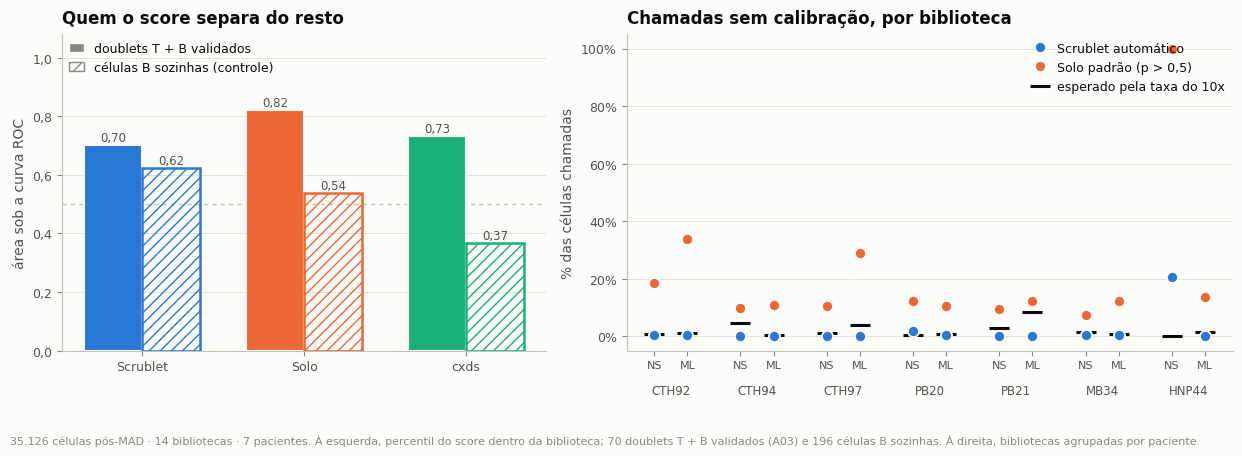

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
xs = np.arange(len(SCORES))
w = 0.36
a1.bar(xs - w / 2, auc["AUC: T + B validados × demais"], width=w, color=[METODO_COR[m] for m in SCORES],
       edgecolor=INK["surface"], linewidth=1.5, zorder=3)
a1.bar(xs + w / 2, auc["AUC: B sozinhas × demais"], width=w, color="none", edgecolor=[METODO_COR[m] for m in SCORES],
       linewidth=1.8, hatch="///", zorder=3)
for x, v1_, v2_ in zip(xs, auc.iloc[:, 0], auc.iloc[:, 1]):
    a1.annotate(F.f(v1_, 2), (x - w / 2, v1_), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5,
                color=INK["secondary"])
    a1.annotate(F.f(v2_, 2), (x + w / 2, v2_), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5,
                color=INK["secondary"])
a1.axhline(0.5, color=INK["axis"], lw=1, ls=(0, (3, 3)), zorder=1)
a1.set_xticks(xs)
a1.set_xticklabels(list(SCORES))
a1.set_ylim(0, 1.08)
plotting.decimals(a1, "y", 1)
a1.set_ylabel("área sob a curva ROC")
a1.set_title("Quem o score separa do resto")
a1.legend(handles=[mpl.patches.Patch(fc=INK["muted"], ec=INK["surface"], label="doublets T + B validados"),
                   mpl.patches.Patch(fc="none", ec=INK["muted"], hatch="///", label="células B sozinhas (controle)")],
          loc="upper left", ncol=1)
a1.grid(axis="x", visible=False)

pos = plotting.library_positions()
x_lib = np.array([pos[l] for l in LIBS])
for nome, col, cor, mk in [("Scrublet automático", "scrublet_auto", METODO_COR["Scrublet"], "o"),
                           ("Solo padrão (p > 0,5)", "solo_padrao", METODO_COR["Solo"], "o")]:
    f = pc.groupby("library_id")[col].mean().reindex(LIBS)
    a2.plot(x_lib, f * 100, ls="", marker=mk, ms=8, mfc=cor, mec=INK["surface"], mew=1.3, label=nome, zorder=3)
a2.plot(x_lib, taxa.reindex(LIBS) * 100, ls="", marker="_", ms=14, mew=2.2, color=INK["primary"], zorder=2,
        label="esperado pela taxa do 10x")
a2.set_xticks(x_lib)
a2.set_xticklabels([l.split("_")[1] for l in LIBS], fontsize=8)
for pat in config.PATIENTS:
    xm = np.mean([pos[f"{pat}_NS"], pos[f"{pat}_ML"]])
    a2.annotate(pat, (xm, 0), xycoords=("data", "axes fraction"), xytext=(0, -24), textcoords="offset points",
                ha="center", va="top", fontsize=8.5, color=INK["secondary"])
a2.set_ylabel("% das células chamadas")
a2.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.f(v, 0) + "%"))
a2.set_title("Chamadas sem calibração, por biblioteca")
a2.legend(loc="upper right")
a2.grid(axis="x", visible=False)
plotting.note(fig, f"{F.n(len(pc))} células pós-MAD · {plotting.N_DESIGN}. À esquerda, percentil do score dentro da biblioteca; "
                   f"{n_tb} doublets T + B validados (A03) e {n_bs} células B sozinhas. À direita, bibliotecas agrupadas por paciente.",
              y=0.0)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plotting.savefig(fig, NB, "comparacao_dos_metodos", description="Separação dos doublets validados e chamadas por biblioteca, por método",
                 data=pc.groupby("library_id")[["scrublet_auto", "solo_padrao"]].mean().reindex(LIBS)
                        .assign(esperado_10x=taxa.reindex(LIBS)).rename_axis("library_id").reset_index(), data_index=False)
plt.show()

## 4. A hipótese da baixa recuperação

Se as bibliotecas com poucas células tivessem perdido células para doublets,
os métodos deveriam marcar **mais** doublets justamente nelas. Com limiar
calibrado a fração chamada é fixada pela taxa do 10x, então a comparação usa
o que não depende de calibração: a chamada padrão do Solo e a distribuição
dos scores em cada biblioteca.

In [9]:
peq = n_lib[n_lib < 2000].index
gra = n_lib[n_lib >= 2000].index
rec = pd.DataFrame({
    "células": n_lib,
    "taxa esperada 10x": taxa,
    "Scrublet automático": pc.groupby("library_id")["scrublet_auto"].mean(),
    "Solo padrão": pc.groupby("library_id")["solo_padrao"].mean(),
    "Solo: p mediana": pc.groupby("library_id")["solo_p"].median(),
    "Solo: p > 0,9": pc.groupby("library_id")["solo_p"].apply(lambda s: (s > 0.9).mean()),
    "UMIs relativos das chamadas do Solo": pc[pc["solo_padrao"]].groupby("library_id")["umis_rel"].median(),
}).reindex(LIBS)
rec["grupo"] = np.where(rec["células"] < 2000, "< 2.000 células", "≥ 2.000 células")
io.save_table(rec, NB, "recuperacao_por_biblioteca", description="Chamadas sem calibração por biblioteca e tamanho da biblioteca")
rho_solo = stats.spearmanr(rec["Solo padrão"], rec["células"]).statistic
print(f"Solo padrão: mediana de {F.pct(rec.loc[peq, 'Solo padrão'].median())} chamadas nas {len(peq)} bibliotecas com menos de "
      f"2.000 células e {F.pct(rec.loc[gra, 'Solo padrão'].median())} nas {len(gra)} maiores; "
      f"Spearman com o nº de células {F.f(rho_solo, 2)}")
print(f"UMIs das células chamadas pelo Solo padrão, relativos à mediana da biblioteca: mediana "
      f"{F.x(pc.loc[pc['solo_padrao'], 'umis_rel'].median())} (não chamadas: {F.x(pc.loc[~pc['solo_padrao'], 'umis_rel'].median())})")
rec.round(3)

Solo padrão: mediana de 12,2% chamadas nas 10 bibliotecas com menos de 2.000 células e 11,0% nas 4 maiores; Spearman com o nº de células -0,29
UMIs das células chamadas pelo Solo padrão, relativos à mediana da biblioteca: mediana 1,86× (não chamadas: 0,95×)


,células,taxa esperada 10x,Scrublet automático,Solo padrão,Solo: p mediana,"Solo: p > 0,9",UMIs relativos das chamadas do Solo,grupo
CTH92_NS,812,0.006,0.004,0.183,0.139,0.057,1.645,< 2.000 células
CTH92_ML,1538,0.012,0.005,0.338,0.340,0.059,1.804,< 2.000 células
CTH94_NS,5579,0.045,0.001,0.097,0.005,0.050,1.941,≥ 2.000 células
CTH94_ML,500,0.004,0.002,0.110,0.076,0.024,1.780,< 2.000 células
CTH97_NS,1517,0.012,0.003,0.105,0.022,0.042,1.843,< 2.000 células
CTH97_ML,4696,0.038,0.000,0.289,0.239,0.030,1.971,≥ 2.000 células
PB20_NS,602,0.005,0.017,0.123,0.110,0.037,1.703,< 2.000 células
PB20_ML,781,0.006,0.005,0.104,0.055,0.031,1.649,< 2.000 células
PB21_NS,3666,0.029,0.000,0.094,0.017,0.037,1.818,≥ 2.000 células
PB21_ML,10629,0.085,0.000,0.122,0.002,0.083,1.949,≥ 2.000 células


## 5. Onde as chamadas caem nos clusters da V3

Doublets heterotípicos tendem a se acumular entre populações ou em clusters
próprios; chamadas espalhadas por toda parte, sem relação com o conteúdo de
RNA, apontam para o método reagindo à variação comum entre células. Os
clusters técnicos de A05 (8: células B e conjugados; 10, 11, 12: não-T) são
a referência.

In [10]:
dentro = pc[pc["cluster_v3"].notna()]
glob = {k: dentro[v].mean() for k, v in CHAMADAS.items() if k != "Scrublet automático"}
enr = pd.DataFrame({k: dentro.groupby("cluster_v3")[CHAMADAS[k]].mean() / g for k, g in glob.items()})
enr = enr.loc[sorted(enr.index, key=int)]
enr.insert(0, "células", dentro.groupby("cluster_v3").size().reindex(enr.index))
io.save_table(enr, NB, "enriquecimento_por_cluster", description="Fração chamada em cada cluster da V3 dividida pela fração global")
print(f"{F.n(len(dentro))} das {F.n(len(pc))} células estão no objeto integrado (as demais saíram pelo Scrublet automático)")
enr.round(2)

35.064 das 35.126 células estão no objeto integrado (as demais saíram pelo Scrublet automático)


,células,Scrublet calibrado,"Solo padrão (p > 0,5)",Solo calibrado,cxds calibrado,consenso (≥ 2 dos 3 calibrados)
cluster_v3,,,,,,
0,8067,1.46,1.24,1.51,1.74,1.76
1,7575,1.23,0.69,0.69,0.55,0.69
2,4997,1.24,0.91,1.03,0.61,0.88
3,4841,0.23,0.49,0.27,0.15,0.10
4,3751,0.37,1.14,1.04,1.61,1.08
5,2012,0.98,1.11,1.33,1.04,1.31
6,1851,0.48,1.82,1.40,1.40,0.87
7,1186,1.44,1.11,0.97,0.74,1.26
8,282,1.41,1.82,1.52,1.36,1.91


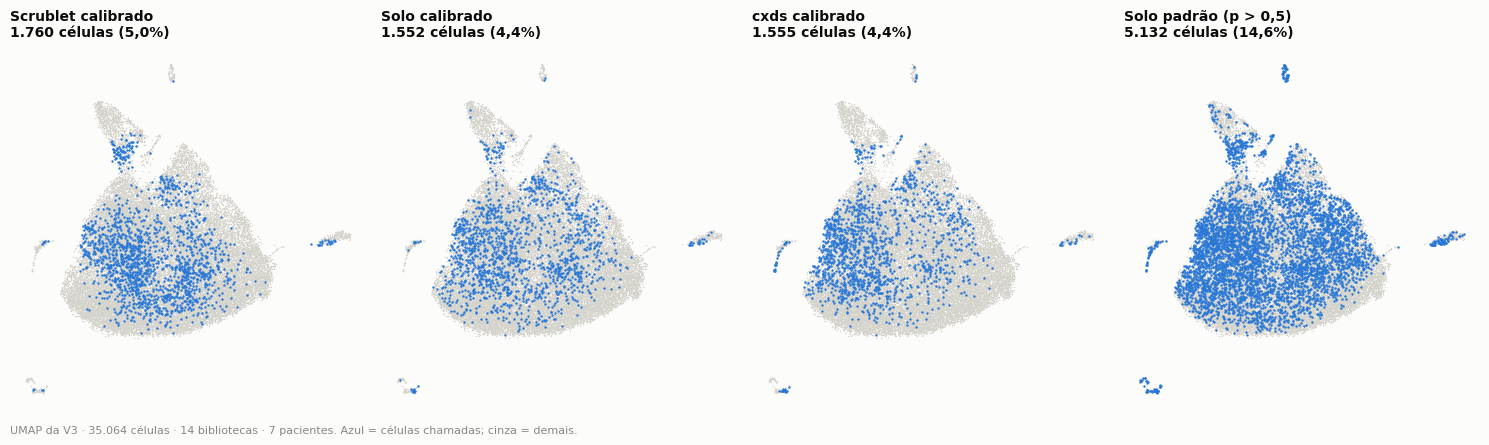

In [11]:
paineis = [("Scrublet calibrado", "scrublet_calibrado"), ("Solo calibrado", "solo_calibrado"),
           ("cxds calibrado", "cxds_calibrado"), ("Solo padrão (p > 0,5)", "solo_padrao")]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.3))
xy = umap.reindex(dentro.index).to_numpy()
for ax, (nome, col) in zip(axes, paineis):
    msk = dentro[col].astype(bool).to_numpy()
    ax.scatter(xy[:, 0], xy[:, 1], s=1.0, c=plotting.CONTEXT, lw=0, rasterized=True)
    ax.scatter(xy[msk, 0], xy[msk, 1], s=3.0, c=plotting.ACCENT, lw=0, rasterized=True)
    ax.set_title(f"{nome}\n{F.n(msk.sum())} células ({F.pct(msk.mean(), 1)})", fontsize=10)
    plotting._umap_axes(ax)
plotting.note(fig, f"UMAP da V3 · {F.n(len(dentro))} células · {plotting.N_DESIGN}. Azul = células chamadas; cinza = demais.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "umap_chamadas", description="Células chamadas por cada método no UMAP da V3",
                 data=enr.rename_axis("cluster").reset_index(), data_index=False)
plt.show()

## 6. Veredito

In [12]:
s_tb = comp["sensibilidade"]
ver = pd.DataFrame([
    ["Scrublet (A03)", f"AUC {F.f(auc.loc['Scrublet', 'AUC: T + B validados × demais'], 2)}; calibrado pega "
                       f"{comp.loc['Scrublet calibrado', 'T + B validados pegos']}",
     f"automático: {F.pct(comp.loc['Scrublet automático', '% das células'], 2)} chamadas"],
    ["Solo", f"AUC {F.f(auc.loc['Solo', 'AUC: T + B validados × demais'], 2)}; calibrado pega "
             f"{comp.loc['Solo calibrado', 'T + B validados pegos']}",
     f"padrão: {F.pct(comp.loc['Solo padrão (p > 0,5)', '% das células'], 1)} chamadas; ρ com o nº de células "
     f"{F.f(rho_solo, 2)}; B sozinhas chamadas {comp.loc['Solo padrão (p > 0,5)', 'B sozinhas chamadas']}"],
    ["cxds", f"AUC {F.f(auc.loc['cxds', 'AUC: T + B validados × demais'], 2)}; calibrado pega "
             f"{comp.loc['cxds calibrado', 'T + B validados pegos']}",
     f"pares que dirigem as chamadas: {', '.join(f'{c} {F.pct(x, 0)}' for c, x in cls_cel.head(3).items())}"],
], columns=["método", "doublets T + B validados", "comportamento"]).set_index("método")
io.save_table(ver, NB, "vereditos", description="Solo e cxds frente ao Scrublet e aos doublets validados")
with pd.option_context("display.max_colwidth", None):
    display(ver)

,doublets T + B validados,comportamento
método,,
Scrublet (A03),"AUC 0,70; calibrado pega 19/70","automático: 0,18% chamadas"
Solo,"AUC 0,82; calibrado pega 20/70","padrão: 14,7% chamadas; ρ com o nº de células -0,29; B sozinhas chamadas 25/196"
cxds,"AUC 0,73; calibrado pega 21/70",pares que dirigem as chamadas: outros × outros 100%


In [13]:
flags = pc[["library_id", "barcode", "solo_p", "solo_padrao", "solo_calibrado", "cxds_score", "cxds_calibrado",
            "consenso"]].reset_index(drop=True)
io.save_data(flags, NB, "flags_solo_cxds", description="Scores e chamadas do Solo e do cxds por célula pós-filtro MAD")

[io] conteúdo mudou — nova versão: flags_solo_cxds__v2.parquet (anterior preservada)


PosixPath('/mnt/SATA/singleCellTaru/dataReseq/A06_doublets_solo_cxds/flags_solo_cxds__v2.parquet')

## Problemas encontrados

In [14]:
sp_ = comp.loc["Solo padrão (p > 0,5)"]
frac_lib_solo = rec["Solo padrão"]
log.add("MAJOR", "Solo (scvi-tools) com o limiar padrão p > 0,5",
        "o Solo superestima doublets em todas as bibliotecas e não serve para remover células",
        evidence=f"{F.n(sp_['chamadas'])} chamadas ({F.pct(sp_['% das células'], 1)}); de {F.pct(frac_lib_solo.drop('HNP44_NS').min(), 0)} a "
                 f"{F.pct(frac_lib_solo.drop('HNP44_NS').max(), 0)} por biblioteca e {F.pct(frac_lib_solo['HNP44_NS'], 0)} em HNP44_NS "
                 f"({int(n_lib['HNP44_NS'])} células), contra taxa esperada do 10x de {F.pct(taxa.min(), 1)} a {F.pct(taxa.max(), 1)}; "
                 f"o score acompanha o conteúdo de RNA (ρ = {F.f(auc.loc['Solo', 'ρ com UMIs (dentro da biblioteca)'], 2)})",
        impact="removendo pelo padrão sairiam ~15% das células, sobretudo as de mais RNA e as das bibliotecas de baixa "
               "complexidade (CTH92_ML, CTH97_ML); com 88 células o classificador degenera",
        recommendation="usar o Solo só como score ordenado, com limiar calibrado pela taxa esperada, e como marca de sensibilidade")
log.add("MAJOR", "hipótese: baixa recuperação por excesso de doublets",
        "nem o Solo nem o cxds indicam mais doublets nas bibliotecas de baixa recuperação",
        evidence=f"Solo padrão: mediana de {F.pct(rec.loc[peq, 'Solo padrão'].median())} chamadas nas {len(peq)} bibliotecas com menos de "
                 f"2.000 células e {F.pct(rec.loc[gra, 'Solo padrão'].median())} nas {len(gra)} maiores; Spearman com o nº de células "
                 f"{F.f(rho_solo, 2)}",
        impact="a conclusão de A03 se mantém com dois métodos de lógica diferente",
        recommendation="nenhuma mudança: a baixa recuperação é questão de carregamento/viabilidade, não de doublets")
top_pares = ", ".join(pares_celula["par"].value_counts().head(3).index)
log.add("MINOR", "cxds (scds) nesta população",
        "os pares 'mutuamente exclusivos' do cxds são genes de programas de célula T, não de linhagens diferentes",
        evidence=f"pares que mais pesam nas células chamadas: {top_pares}; nenhum par com marcador de B entre os mais exclusivos; "
                 f"células B sozinhas têm score baixo (AUC {F.f(auc.loc['cxds', 'AUC: B sozinhas × demais'], 2)}); "
                 f"o score acompanha o nº de UMIs (ρ = {F.f(auc.loc['cxds', 'ρ com UMIs (dentro da biblioteca)'], 2)})",
        impact="o cxds marca células que coexpressam dois programas de célula T; não separa um doublet de duas células T "
               "diferentes de uma célula em estado intermediário",
        recommendation="usar como marca de sensibilidade, não como filtro")
cons_ = comp.loc["consenso (≥ 2 dos 3 calibrados)"]
log.add("MINOR", "concordância entre detectores",
        "Scrublet, Solo e cxds concordam pouco e pegam ~30% dos doublets validados no limiar calibrado",
        evidence=f"Jaccard entre os calibrados de {F.f(jac.loc[['Scrublet calibrado', 'Solo calibrado', 'cxds calibrado'], ['Scrublet calibrado', 'Solo calibrado', 'cxds calibrado']].where(lambda d: d < 1).min().min(), 2)} a "
                 f"{F.f(jac.loc[['Scrublet calibrado', 'Solo calibrado', 'cxds calibrado'], ['Scrublet calibrado', 'Solo calibrado', 'cxds calibrado']].where(lambda d: d < 1).max().max(), 2)}; "
                 f"T + B validados pegos: Scrublet {comp.loc['Scrublet calibrado', 'T + B validados pegos']}, Solo "
                 f"{comp.loc['Solo calibrado', 'T + B validados pegos']}, cxds {comp.loc['cxds calibrado', 'T + B validados pegos']}; "
                 f"consenso (≥ 2 de 3): {F.n(cons_['chamadas'])} células, {cons_['T + B validados pegos']} validados",
        impact="não há um conjunto de doublets que os métodos reconheçam em comum; remover pela união tiraria ~10% das células",
        recommendation="manter as células; carregar o consenso como coluna de sensibilidade na anotação e remover os T + B validados "
                       "e os clusters técnicos de A05")
log.add("INFO", "reimplementação do cxds", "[VERIFICAÇÃO] a reimplementação em Python reproduz o pacote scds",
        evidence=conf_cxds, impact="os scores do cxds equivalem aos do scds 2.0.0",
        recommendation="nenhuma")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       2
MINOR       2
INFO        1


severity,location,problem,evidence,impact,recommendation
MAJOR,"Solo (scvi-tools) com o limiar padrão p > 0,5",o Solo superestima doublets em todas as bibliotecas e não serve para remover células,"5.175 chamadas (14,7%); de 7% a 34% por biblioteca e 100% em HNP44_NS (88 células), contra taxa esperada do 10x de 0,1% a 8,5%; o score acompanha o conteúdo de RNA (ρ = 0,75)","removendo pelo padrão sairiam ~15% das células, sobretudo as de mais RNA e as das bibliotecas de baixa complexidade (CTH92_ML, CTH97_ML); com 88 células o classificador degenera","usar o Solo só como score ordenado, com limiar calibrado pela taxa esperada, e como marca de sensibilidade"
MAJOR,hipótese: baixa recuperação por excesso de doublets,nem o Solo nem o cxds indicam mais doublets nas bibliotecas de baixa recuperação,"Solo padrão: mediana de 12,2% chamadas nas 10 bibliotecas com menos de 2.000 células e 11,0% nas 4 maiores; Spearman com o nº de células -0,29",a conclusão de A03 se mantém com dois métodos de lógica diferente,"nenhuma mudança: a baixa recuperação é questão de carregamento/viabilidade, não de doublets"
MINOR,cxds (scds) nesta população,"os pares 'mutuamente exclusivos' do cxds são genes de programas de célula T, não de linhagens diferentes","pares que mais pesam nas células chamadas: PHACTR2 × IGF1R, IGF1R × ERN1, CD7 × TALAM1; nenhum par com marcador de B entre os mais exclusivos; células B sozinhas têm score baixo (AUC 0,37); o score acompanha o nº de UMIs (ρ = 0,74)",o cxds marca células que coexpressam dois programas de célula T; não separa um doublet de duas células T diferentes de uma célula em estado intermediário,"usar como marca de sensibilidade, não como filtro"
MINOR,concordância entre detectores,"Scrublet, Solo e cxds concordam pouco e pegam ~30% dos doublets validados no limiar calibrado","Jaccard entre os calibrados de 0,20 a 0,40; T + B validados pegos: Scrublet 19/70, Solo 20/70, cxds 21/70; consenso (≥ 2 de 3): 1.180 células, 20/70 validados",não há um conjunto de doublets que os métodos reconheçam em comum; remover pela união tiraria ~10% das células,manter as células; carregar o consenso como coluna de sensibilidade na anotação e remover os T + B validados e os clusters técnicos de A05
INFO,reimplementação do cxds,[VERIFICAÇÃO] a reimplementação em Python reproduz o pacote scds,"scds CTH92_NS: 812 células; maior diferença relativa 5.3e-02; Spearman 0,999931",os scores do cxds equivalem aos do scds 2.0.0,nenhuma


## Conclusão

**Nenhum dos dois métodos sustenta a hipótese de que doublets expliquem a
baixa recuperação.** O Solo, com o limiar padrão, chama mais ou menos a mesma
fração em bibliotecas pequenas e grandes (mediana de 12,2% nas 10 com menos
de 2.000 células e 11,0% nas 4 maiores; ρ = −0,29 com o número de células).
Sob a hipótese, as pequenas deveriam ter mais.

**O limiar padrão do Solo não é uma taxa de doublets.** Ele marca 14,7% das
células — de 7% a 34% por biblioteca e todas as 88 de HNP44_NS —, quando a
física do carregamento permite no máximo 0,1% a 8,5%. A régua de RNA de A03
põe o teto de doublets T + T em 0–4,1% nas bibliotecas pequenas. O score do
Solo acompanha o conteúdo de RNA da célula (ρ = 0,75); por isso as células
chamadas têm ~1,9× os UMIs da mediana, como teria qualquer seleção da cauda
superior da distribuição. Ele chama mais nas bibliotecas de baixa
complexidade (CTH92_ML 34%, CTH97_ML 29%).

**O cxds, nesta população, não procura linhagens.** Os 500 genes de maior
variância de presença são de programas de célula T, e os pares "mutuamente
exclusivos" opõem genes como IGF1R, ADTRP e ACTN1 a PHACTR2, S100A4, NIBAN1 e
ITGB1. O cxds marca, então, células que coexpressam dois programas de célula T
— um doublet de duas células diferentes ou uma célula em estado
intermediário, sem como separar. As células B sozinhas recebem score baixo
(AUC 0,37), o que é o comportamento certo.

**Como ordenadores, os três métodos são modestos e discordam.** Contra os 70
doublets T + B validados, o Solo separa melhor (AUC 0,82), seguido de cxds
(0,73) e Scrublet (0,70). No limiar calibrado pela taxa do 10x, cada um pega
19–21 dos 70, e os conjuntos chamados se sobrepõem pouco (Jaccard 0,20–0,40).
O consenso — células marcadas por pelo menos 2 dos 3 — tem 1.180 células
(3,4%) e contém 20 dos 70 validados.

**O que fazer.** Não remover células por nenhum desses métodos. Remover os
doublets T + B validados e os clusters técnicos de A05, e carregar o consenso
como coluna de sensibilidade na anotação: se um cluster for formado
principalmente por células do consenso, ele merece desconfiança.

In [15]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

16 artefatos gravados por este notebook:
                      name    kind
cxds_pares_mais_exclusivos   table
    cxds_classes_dos_pares   table
       solo_por_biblioteca   table
    comparacao_dos_metodos   table
            auc_dos_scores   table
      concordancia_jaccard   table
       concordancia_scores   table
fig_comparacao_dos_metodos  figure
fig_comparacao_dos_metodos   table
recuperacao_por_biblioteca   table
enriquecimento_por_cluster   table
         fig_umap_chamadas  figure
         fig_umap_chamadas   table
                 vereditos   table
           flags_solo_cxds parquet
                    issues   table
